# TP3 — RAG multimodal et agentique

| Informations académiques | Détails |
|---|---|
| **Nom et prénom** | Hachoum Mouad |
| **Filière** | INTELLIGENCE ARTIFICIELLE & SCIENCES DES DONNÉES |
| **Année universitaire** | 2026-2027 |
| **Module** | IA Générative Multimodale |
| **Enseignant** | Pr. Mohamed Youssfi |

**Objectif :** extraire, indexer et interroger le texte et les figures d’un PDF,
puis construire un agent documentaire local, une interface Streamlit et une séparation
Agent/RAG par MCP. Le notebook suit les sept étapes du support officiel
`rag_multimodal_agentique.ipynb`, notamment « Suite à compléter » (cellules 54–55).
Les fonctions réutilisables figurent dans `src/tp3rag` : le notebook, l’interface et
MCP utilisent le même pipeline. Le support original et les données restent locaux.

**Corpus :** *Attention Is All You Need*, Vaswani et al. (2017), PDF fourni de 11 pages.
Ses chiffres sont vérifiés dans cette version ; elle annonce 41,0 BLEU pour
l’anglais-français, alors que certaines révisions ultérieures indiquent 41,8.
Voir [SOURCES.md](SOURCES.md). Les contenus documentaires sont des données à analyser,
jamais des instructions à exécuter.

## Phase 0 — Environnement local

Depuis `TP3` : `uv sync --locked`, puis sélectionner `.venv` et exécuter toutes les
cellules dans l’ordre depuis un noyau neuf. Python 3.11 ; aucune API payante.
Les modèles préentraînés sont utilisés en inférence, sans entraînement.

**Édition publique :** Version publique dérivée de l’exécution locale : textes récupérés, réponses documentaires et figures reproduites retirés ; métriques, identifiants et pages conservés. Aucune expérience relancée. Les sorties complètes se régénèrent localement en exécutant le code. Voir [PUBLICATION.md](PUBLICATION.md).

<TP3>\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Python : 3.11.9 | PyTorch : 2.9.1+cu128
CUDA disponible : True
GPU : NVIDIA GeForce RTX 3060 Laptop GPU
LLM local : qwen3-vl:4b-instruct-q4_K_M
Contrôles réels vision/outils : Rouge et bleu [{'nom': 'additionner', 'arguments': {'a': 7, 'b': 5}, 'resultat': 12}]


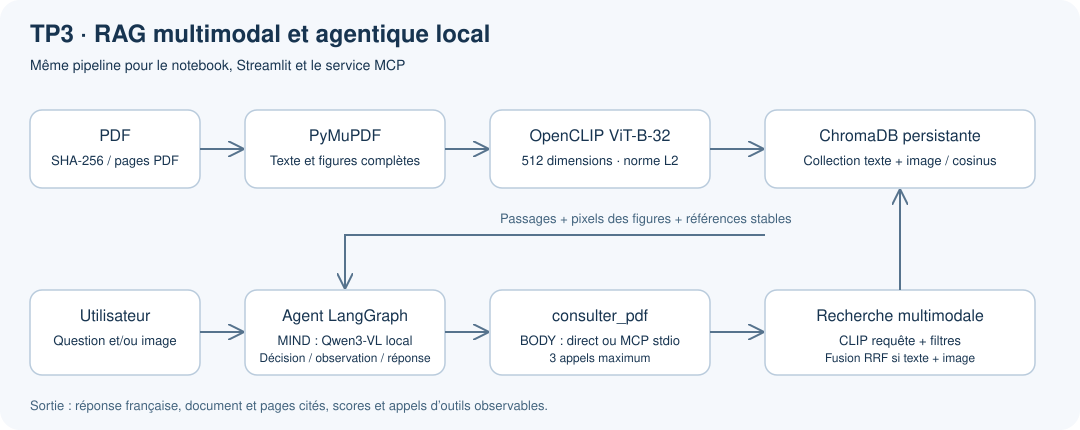

In [1]:
import json
import platform
import random
from pathlib import Path
import numpy as np
import torch
from IPython.display import display, Markdown, SVG
from PIL import Image
from tp3rag.config import ROOT, Settings, lire_json, ecrire_json
from tp3rag.extraction import extraire
from tp3rag.retrieval import RagStore

random.seed(42)
np.random.seed(42)
torch.manual_seed(42)
torch.set_num_threads(4)
settings = Settings()
store = RagStore(settings)
pdf = settings.data / 'pdfs' / 'attention_is_all_you_need.pdf'
print('Python :', platform.python_version(), '| PyTorch :', torch.__version__)
print('CUDA disponible :', torch.cuda.is_available())
print('GPU :', torch.cuda.get_device_name() if torch.cuda.is_available() else 'CPU')
print('LLM local :', settings.model)
capacites = lire_json(ROOT / '.cache' / 'capabilities.json')
if not capacites:
    from tp3rag.llm import verifier_capacites
    capacites = verifier_capacites(settings)
    ecrire_json(ROOT / '.cache' / 'capabilities.json', capacites)
assert capacites['vision']['succes'] and capacites['tool_calling']['succes']
print('Contrôles réels vision/outils :', capacites['vision']['reponse'], capacites['tool_calling']['appels_reels'])
display(SVG(filename=str(ROOT / 'docs' / 'architecture.svg')))

## 1. Extraction multimodale — PyMuPDF

Chaque document est identifié par le SHA-256 complet de ses octets. Le texte est
enregistré par page et dans un fichier global. Les images intégrées identiques
partagent un fichier ; les figures composées ou vectorielles peuvent être rendues
dans la région précédant leur légende. La numérotation correspond aux pages PDF, à partir de 1.
Dans le corpus fourni, la figure 2 contient deux sous-images : on les regroupe
pour indexer le mécanisme complet, sans doublonner leurs composants.

In [2]:
extraction = extraire(pdf, settings)
print('Document SHA-256 :', extraction['document_id'])
print('Pages :', extraction['pages'])
print('Images intégrées uniques :', extraction['images_integrees_uniques'])
print('Figures complètes retenues :', len(extraction['images']))
print('Pages sans texte :', extraction['pages_sans_texte'])
texte = settings.chemin(extraction['textes'][0]['source']).read_text(encoding='utf-8')
print('Aperçu de l’abstract :', texte.split('Abstract')[-1][:350])
for item in extraction['images']:
    print(f"Figure {item['figure']} — page PDF {item['page']} — {item['methode']}")
    with Image.open(settings.chemin(item['source'])) as image:
        apercu = image.convert('RGB')
        apercu.thumbnail((600, 500))
        display(apercu)
display(Markdown('Figures : Vaswani et al., *Attention Is All You Need* (2017), pages PDF 3 et 4 du corpus fourni.'))

Pages PDF : 11
Images intégrées uniques : 3
Figures indexées : 2
[Contenu documentaire retiré de la version publique ; disponible dans la copie locale complète.]


## 2. Embeddings multimodaux — OpenCLIP

Le modèle du professeur est conservé : **ViT-B-32**, poids **laion2b_s34b_b79k**,
**512 dimensions**. Une fenêtre contient 60 tokens CLIP, avec 10 tokens de
chevauchement. Les identifiants de tokens sont conservés directement pour construire
les entrées (marqueurs début/fin compris dans le contexte de 77 tokens).
Le texte des preuves est reconstruit par ses plages de caractères pour préserver
les nombres : le décodage BPE naïf séparerait les chiffres de `512` ou `28.4`.

Les pixels sont encodés par l’encodeur visuel, pas par une légende ou un nom de fichier.
Les calculs utilisent `torch.inference_mode()`, des lots et la normalisation L2.
Une instance du modèle est conservée par processus ; les poids en cache sont réutilisés.

In [3]:
encoder = store.encoder
chunks_exemple = list(encoder.decouper_texte('The Transformer uses attention. ' * 30))
print('Longueurs en tokens :', [len(c['tokens']) for c in chunks_exemple])
print('Chevauchement exact :', chunks_exemple[0]['tokens'][-10:] == chunks_exemple[1]['tokens'][:10])
vecteurs = encoder.encoder_textes(['Transformer model architecture', 'Scaled dot product attention'])
print('Dimensions :', vecteurs.shape, '| normes :', np.linalg.norm(vecteurs, axis=1).round(6).tolist())
assert vecteurs.shape == (2, 512) and np.isfinite(vecteurs).all()
assert np.allclose(np.linalg.norm(vecteurs, axis=1), 1, atol=1e-5)
print('Périphérique OpenCLIP :', encoder.device)

Longueurs en tokens : [60, 60, 50]
Chevauchement exact : True


Dimensions : (2, 512) | normes : [1.0, 1.0]
Périphérique OpenCLIP : cuda


## 3. Indexation persistante — ChromaDB

Une collection commune contient textes et images, avec `embedding_function=None`
et une distance cosinus. Son nom et ses métadonnées identifient la configuration
d’embedding ; des modèles différents ne partagent pas la même collection.
Les identifiants déterministes combinent document, modalité, page et fragment ou
empreinte d’image. Les upserts empêchent les doublons et réutilisent les vecteurs
existants d’un document identique. Une version modifiée remplace l’ancienne sous
le même alias, après l’indexation réussie des nouveaux éléments.

In [4]:
bilan = store.indexer(pdf)
print(json.dumps({k: v for k, v in bilan.items() if k != 'embedding'}, ensure_ascii=False, indent=2))
print('Configuration :', store.collection.metadata['embedding_config'])
print('Éléments persistants :', store.collection.count())

{
  "document_id": "3c5f5a2cb399bc8fdff13f5d6da8987e185e27695307360de52bc4ea3c8e5af3",
  "pdf": "attention_is_all_you_need.pdf",
  "pages": 11,
  "chunks": 171,
  "images": 2,
  "total": 173,
  "reutilise": true,
  "duree_secondes": 0.04059910000069067
}
Configuration : {"chunk_tokens": 60, "dimension": 512, "metric": "cosine", "model": "ViT-B-32", "overlap": 10, "pretrained": "laion2b_s34b_b79k"}
Éléments persistants : 173


## 4. Recherche multimodale

Les quatre directions sont disponibles : texte→texte, texte→image, image→texte,
image→image. L’image de requête est enregistrée sous un identifiant contrôlé ;
l’agent ne peut pas demander la lecture d’un chemin arbitraire.
Si texte et image sont fournis ensemble, deux recherches sont fusionnées par
**Reciprocal Rank Fusion**, constante 60, au plus 48 candidats par entrée.
Les cosinus de chaque entrée restent distincts du score RRF. Aucun de ces scores
n’est une probabilité de vérité. `k` est limité au nombre de résultats du filtre.
Lorsqu’une requête d’images nomme explicitement « figure n », ce numéro impose
un filtre de métadonnées avant le classement cosinus, pour ne pas confondre les figures.

In [5]:
figure1 = next(x for x in extraction['images'] if x['figure'] == 1)
image_id = store.register_image(settings.chemin(figure1['source']).read_bytes())
requetes = [
    ('Texte → texte', {'texte': 'scaled dot product attention divide square root key dimension', 'type_resultat': 'texte'}),
    ('Texte → image', {'texte': 'Scaled Dot Product Attention Multi Head Attention two diagrams', 'type_resultat': 'image'}),
    ('Image → texte', {'image_id': image_id, 'type_resultat': 'texte'}),
    ('Image → image', {'image_id': image_id, 'type_resultat': 'image'}),
    ('Recherche mixte', {'texte': 'Transformer model architecture', 'type_resultat': 'tous'}),
    ('Hybride texte + image', {'texte': 'encoder decoder architecture', 'image_id': image_id, 'type_resultat': 'tous'}),
]
for nom, arguments in requetes:
    print('\n' + nom)
    for source in store.rechercher(**arguments, k=2):
        m = source['metadata']
        print(f"{source['rang']}. {m['type']} | page {m['page']} | cosinus {source['similarite_cosinus']:.4f} | {source['classement']}")
        print('Scores par entrée :', source['similarites'])
        print(source['contenu'][:150])

Texte → texte
1. texte | page 3 | cosinus 0.7583 | cosinus CLIP
Scores par entrée : {'texte': 0.758307933807373}
2. texte | page 4 | cosinus 0.6798 | cosinus CLIP
Scores par entrée : {'texte': 0.6797919869422913}
Texte → image
1. image | page 4 | cosinus 0.4489 | cosinus CLIP
Scores par entrée : {'texte': 0.4488622546195984}
2. image | page 3 | cosinus 0.2504 | cosinus CLIP
Scores par entrée : {'texte': 0.25042635202407837}
Image → texte
1. texte | page 6 | cosinus 0.3282 | cosinus CLIP
Scores par entrée : {'image': 0.3281921148300171}
2. texte | page 3 | cosinus 0.3172 | cosinus CLIP
Scores par entrée : {'image': 0.3171922564506531}
Image → image
1. image | page 3 | cosinus 0.9998 | cosinus CLIP
Scores par entrée : {'image': 0.9998341798782349}
2. image | page 4 | cosinus 0.6934 | cosinus CLIP
Scores par entrée : {'image': 0.6934466361999512}
Recherche mixte
1. texte | page 8 | cosinus 0.7430 | cosinus CLIP
Scores par entrée : {'texte': 0.7429618835449219}
2. texte | page 2 | cosinus 

## 5. RAG et outil documentaire

`recuperer_sources` renvoie les contenus, scores, identifiants et métadonnées.
`generer_reponse` ajoute les véritables pixels des figures au contexte du VLM local,
avec les passages et références stables. Les réponses sont demandées en français,
avec citations et reconnaissance des preuves manquantes. Les références inconnues
sont signalées ; ce contrôle mécanique ne prouve pas l’appui de chaque affirmation.
Un échec de format peut déclencher une seconde génération locale, enregistrée
comme correction réelle ; une référence toujours inconnue bloque la réponse.
L’outil LangChain `consulter_pdf` expose la même récupération à l’agent.

In [6]:
from tp3rag.generation import rag
rag_direct = await rag(store, 'Explique la figure 2 et ses deux mécanismes d’attention.', type_resultat='image', k=2)
display(Markdown(rag_direct['reponse']))
print('Images réellement transmises :', rag_direct['images_transmises'])
print('Références reconnues :', rag_direct['citations_valides'])

[Contenu documentaire retiré de la version publique ; disponible dans la copie locale complète.]


Images réellement transmises : 1
Références reconnues : True


## 6. Agent ReAct avec LangGraph

**MIND :** Qwen3-VL 4B Instruct quantifié Q4_K_M, déjà disponible localement.
Ses capacités vision et tool calling ont été testées avant sa sélection.
**BODY :** l’outil de récupération multimodale. `StateGraph` et `MessagesState`
orchestrent décision → `ToolNode` → observation → décision ou réponse.
Un compteur impose trois appels d’outils maximum, même si le modèle en demande
davantage ; la limite de récursion est fixée à 12. Les traces décrivent les appels
observables, sans demander de raisonnement interne privé.
Les instructions demandent de vérifier la couverture de toutes les composantes
de la question et l'appui précis de chaque affirmation dans la source citée.
Une information manquante motive une recherche ciblée, dans le même budget.
Une passe réelle de relecture par le modèle vérifie la réponse proposée avant
sa finalisation ; elle demande un nouvel appel documentaire sur le point le
moins étayé lorsqu'un appel reste disponible. Ce mécanisme
n'est pas un contrôle sémantique indépendant et ne garantit pas la fidélité.
Pour tenir dans le contexte local, les observations sont dédupliquées et limitées
à 12 preuves, avec priorité aux recherches récentes. Les erreurs et les traces
complètes sont conservées ; cette sélection ne prouve pas une absence dans le PDF.
Une image fournie est transmise au VLM et liée côté application aux appels de
recherche : l’omission de son identifiant par le modèle ne supprime pas l’entrée visuelle.

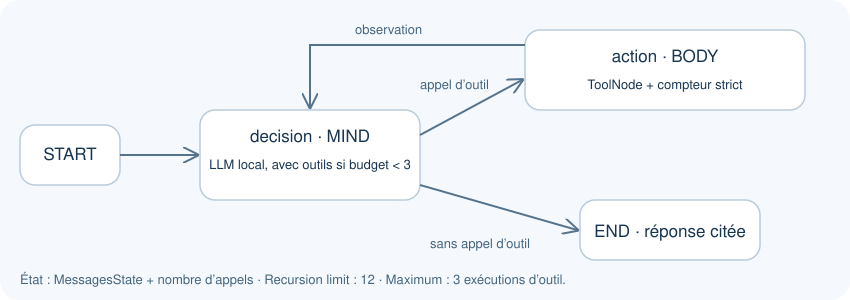

---
config:
  flowchart:
    curve: linear
---
graph TD;
	__start__([<p>__start__</p>]):::first
	decision(decision)
	action(action)
	__end__([<p>__end__</p>]):::last
	__start__ --> decision;
	action --> decision;
	decision -.-> __end__;
	decision -.-> action;
	classDef default fill:#f2f0ff,line-height:1.2
	classDef first fill-opacity:0
	classDef last fill:#bfb6fc



[Contenu documentaire retiré de la version publique ; disponible dans la copie locale complète.]


consulter_pdf [requête textuelle masquée] | sources : 6 | secondes : 0.023
consulter_pdf [requête textuelle masquée] | sources : 3 | secondes : 0.022
Budget respecté : True


In [7]:
from tp3rag.agent import agent_direct
agent = agent_direct(store, extraction['document_id'])
graphe = agent.compiler([], {}, {})
assert {'decision', 'action'}.issubset(graphe.get_graph().nodes)
display(SVG(filename=str(ROOT / 'docs' / 'agent.svg')))
print(graphe.get_graph().draw_mermaid())
demo_agent = await agent.aask('Quelle est la contribution principale du Transformer ?', type_resultat='texte', k=6)
display(Markdown(demo_agent['reponse']))
for appel in demo_agent['appels_outils']:
    print(appel['outil'], appel['arguments'], '| sources :', len(appel.get('resultats', {}).get('sources', [])), '| secondes :', round(appel['duree_secondes'], 3))
print('Budget respecté :', demo_agent['budget_respecte'])

## 7. Tests et validation sur le corpus annoté

Les 15 cas couvrent la contribution du Transformer, l’attention scalée et multi-têtes,
l’encodage positionnel, le masquage, les figures 1 et 2, les requêtes image et hybride,
la comparaison de notions, les paramètres Base, BLEU, une information absente et une
salutation. Les pages et chiffres attendus sont annotés dans `tests/cases.json` à
partir du PDF fourni, identifié par son SHA-256.

**Hit@6 par page** mesure si au moins une page pertinente est récupérée ; les figures
utilisent **Hit@1**. Cette annotation par page est plus large qu’un jugement de chaque
chunk. Les motifs dans les réponses et la validité des références sont des indicateurs
partiels, pas une mesure de vérité complète. Une recherche d’image identique à une
figure de l’index est un test de fonctionnement, sans portée de généralisation.
La validation suivante appelle réellement le modèle, les outils et MCP.
La référence initiale est conservée dans `evaluations/reference_initiale` (11/15
contrôles lexicaux). Les quatre cas signalés sont exécutés en premier, puis les
onze autres vérifient les régressions ; aucun motif attendu n'est modifié.
L'analyse sémantique des réponses et des passages effectivement cités est une
relecture qualitative distincte, documentée dans `evaluations/relecture_semantique.json`.

Après modification, le score lexical reste à 11/15 : le cas positionnel devient
conforme, alors que le cas image→texte utilise « encodage/décodage » au lieu des
termes attendus. Cela ne prouve pas une régression conceptuelle, mais ses citations
restent partielles. La contribution et les valeurs Base restent incomplètes ; le
masquage causal est expliqué sans le mot attendu et avec une preuve citée insuffisante.
La relecture ne permet donc pas de conclure à une amélioration globale de fidélité.

In [8]:
from tp3rag.validation import valider
rapport = await valider(store, prioritaires=('contribution', 'position', 'mask', 'base'))
print(json.dumps(rapport['infrastructure'], ensure_ascii=False, indent=2))
print(json.dumps(rapport['mesures'], ensure_ascii=False, indent=2))
for cas in rapport['cas']:
    print(cas['id'], '|', cas['statut'], '| Hit :', cas.get('recherche', {}).get('hit'),
          '| appels :', cas.get('agent', {}).get('nombre_appels'), '| contrôles :', cas.get('controles', {}))

Validation réelle 1/15 : contribution


Validation réelle 2/15 : position


Validation réelle 3/15 : mask


Validation réelle 4/15 : base


Validation réelle 5/15 : scaled_attention


Validation réelle 6/15 : multi_head


... (6 outputs left out)

Validation réelle 13/15 : bleu


Validation réelle 14/15 : absent


Validation réelle 15/15 : salutation


{
  "reindexation_sans_doublon": true,
  "persistance_autre_processus": true,
  "norme_min": 0.9999999352436634,
  "norme_max": 1.0000001837842742,
  "dimension": 512,
  "vecteurs_finis": true,
  "metadonnees_valides": true,
  "vecteurs_sha256_avant": "bd357e9d9f663d322283b1ab68527d3cef1d289493d1bf4f714ab2f702051c49",
  "vecteurs_sha256_apres": "bd357e9d9f663d322283b1ab68527d3cef1d289493d1bf4f714ab2f702051c49",
  "vecteurs_existants_preserves": true
}
{
  "recherche_hit_par_page": 13,
  "recherche_cas_annotes": 13,
  "hit_rate_pages": 1.0,
  "agents_executes": 15,
  "nombre_cas": 15,
  "references_inconnues": 0,
  "corrections_format_reelles": 1,
  "references_initiales_inconnues": 0,
  "images_requete_effectivement_utilisees": true,
  "controles_motifs_reussis": 11,
  "budget_3_respecte": true,
  "temps_agent_moyen_secondes": 12.450091799999548
}
contribution | succes | Hit : True | appels : 2 | contrôles : {'motifs_reponse': False, 'references_connues': True, 'citations_presentes': T

## Extension A — Interface Streamlit

`uv run streamlit run app.py` ouvre l’interface locale : import PDF, indexation ou
réutilisation, question textuelle et image de requête, filtres, sources, scores,
images et appels d’outils. Le pipeline est importé depuis `src/tp3rag`.
Le bouton « Rechercher avec l’image seule » fonctionne sans texte et conserve
une requête d'embedding exclusivement visuelle.
AppTest importe les vrais octets du PDF et d'une figure et teste l'indexation,
la sélection, les requêtes hybrides et l'image seule avec OpenCLIP et Ollama.
Cette validation ne remplace pas le geste du sélecteur natif ni le transfert
navigateur, qui restent non validés : voir `docs/verification_manuelle.md`.

In [9]:
print(json.dumps({k: v for k, v in rapport['streamlit'].items() if not k.startswith('recherche_')}, ensure_ascii=False, indent=2))

{
  "statut": "succes",
  "methode": "Streamlit AppTest, fichiers réels, sans mock de la recherche ou du LLM",
  "demarrage": true,
  "indicateurs": 3,
  "chat_reel": true,
  "import_pdf_octets_reels": true,
  "indexation_et_selection": true,
  "import_image_octets_reels": true,
  "sources_et_appels_affiches": true,
  "vecteurs_index_preserves": true,
  "vecteurs_sha256": "bd357e9d9f663d322283b1ab68527d3cef1d289493d1bf4f714ab2f702051c49",
  "duree_secondes": 41.2600031999973,
  "gestes_upload_navigateur": "non_valide",
  "note": "AppTest valide les composants et leur backend avec les vrais fichiers. Le sélecteur natif et le transfert navigateur restent à vérifier manuellement.",
  "serveur_http": {
    "port": 8503,
    "status": 200,
    "health": "ok"
  }
}


## Extension B — Agent séparé du service RAG par MCP

`mcp_server.py` expose le retriever ; `mcp_client.py` découvre `consulter_pdf`,
transmet ses arguments par stdio et alimente le même agent LangGraph.
Les figures récupérées traversent le protocole avec leurs pixels Base64 ; les
traces publiques en conservent les références et le nombre, sans copier le Base64.
Le serveur n’accepte aucun chemin de requête arbitraire. Les résultats ci-dessous
proviennent de la véritable exécution MCP incluse dans la validation précédente.

In [10]:
print('MCP :', rapport['mcp']['statut'])
if rapport['mcp']['statut'] == 'succes':
    print('Outils découverts :', rapport['mcp']['outils_decouverts'])
    print('Images reçues via MCP :', rapport['mcp']['images_recues'])
    sortie_mcp = rapport['mcp']['agent']
    display(Markdown(sortie_mcp['reponse']))
    print('Appels réels :', sortie_mcp['nombre_appels'], '| transport :', sortie_mcp['transport'])

MCP : succes
Outils découverts : ['consulter_pdf']
Images reçues via MCP : 2


[Contenu documentaire retiré de la version publique ; disponible dans la copie locale complète.]


Appels réels : 2 | transport : mcp-stdio


## Conclusion

Le pipeline relie extraction multimodale, espace CLIP commun, recherche persistante
et génération locale. L’agent peut rechercher plusieurs fois et reçoit les images
réellement récupérées. MCP sépare l’exécution du service de recherche de celle de
l’agent ; Streamlit réutilise les mêmes composants.

Les limites restent celles d’un petit corpus, d’un encodeur CLIP surtout anglophone
et d’un VLM local de 4 milliards de paramètres. Les équations extraites en texte et
les détails de figures peuvent être imparfaits. Une citation syntaxiquement valide
ne garantit pas la fidélité scientifique d’une réponse ; les résultats sont à lire
avec les sources et les contrôles détaillés.

In [11]:
m = rapport['mesures']
display(Markdown(f"""
**Bilan réel :** {rapport['corpus']['pages']} pages, {rapport['corpus']['chunks']} chunks,
{rapport['corpus']['images']} figures ; {m['agents_executes']}/15 cas agent exécutés.
Hit par page/figure : {m['recherche_hit_par_page']}/{m['recherche_cas_annotes']} cas annotés.
Contrôles de motifs réussis : {m['controles_motifs_reussis']}/15.
Référence initiale conservée : {rapport['comparaison_reference']['motifs_avant']}/15.
Références inconnues : {m['references_inconnues']}.
Budget de trois appels respecté : {m['budget_3_respecte']}.
MCP : {rapport['mcp']['statut']} ; Streamlit AppTest : {rapport['streamlit']['statut']}.
Ces chiffres ne mesurent pas une précision générale sur des documents nouveaux.
"""))
print('Rapport enregistré : resultats_tp3.json')


**Bilan réel :** 11 pages, 171 chunks,
2 figures ; 15/15 cas agent exécutés.
Hit par page/figure : 13/13 cas annotés.
Contrôles de motifs réussis : 11/15.
Référence initiale conservée : 11/15.
Références inconnues : 0.
Budget de trois appels respecté : True.
MCP : succes ; Streamlit AppTest : succes.
Ces chiffres ne mesurent pas une précision générale sur des documents nouveaux.


Rapport enregistré : resultats_tp3.json


## Références

- **Pr. Mohamed Youssfi**, `rag_multimodal_agentique.ipynb`, support officiel : CLIP,
  extraction PyMuPDF, ChromaDB et recherche (cellules 6–53), extensions (54–55),
  RAG et exemples agentiques (57–120). L’accès distant illustré dans le support est
  remplacé par un LLM local ; limites d’outils, références stables et MCP sont implémentés.
- **Vaswani et al. (2017)**, [Attention Is All You Need](https://arxiv.org/abs/1706.03762).
  Le corpus effectivement évalué est le PDF fourni de 11 pages ; les chiffres sont
  contrôlés dans ce fichier et non repris d’une autre version.
- [OpenCLIP](https://github.com/mlfoundations/open_clip), [ChromaDB](https://docs.trychroma.com/),
  [LangGraph](https://docs.langchain.com/oss/python/langgraph/overview),
  [Ollama](https://docs.ollama.com/), [Streamlit](https://docs.streamlit.io/),
  [MCP Python SDK](https://github.com/modelcontextprotocol/python-sdk),
  [UV](https://docs.astral.sh/uv/).

Intégration, rédaction et validation préparées pour Hachoum Mouad avec l’assistance
de Codex. Les éléments pédagogiques et figures restent attribués à leurs sources.